#Лабораторная работа №2

**Таранчев М.П. 251-952**

In [3]:
import numpy as np
import matplotlib.pyplot as plt

##Задание 1

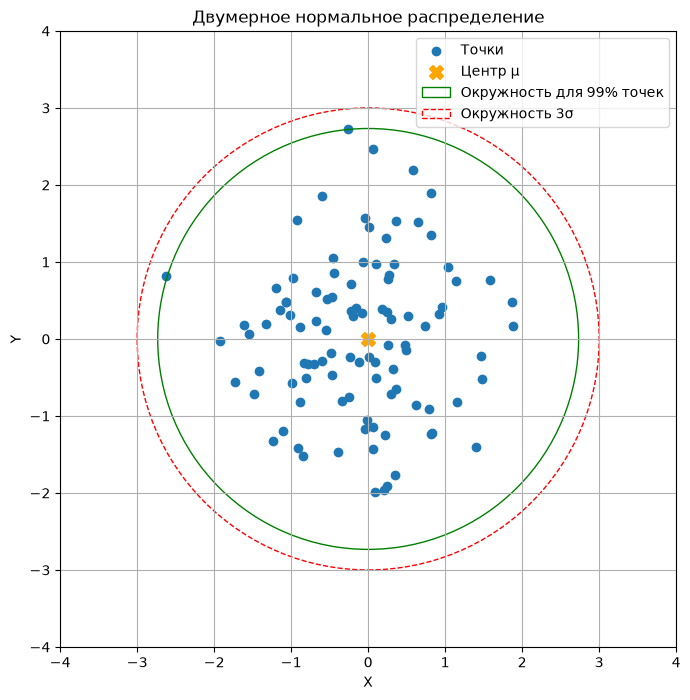

Всего точек: 100
Внутри окружности 99%: 99
Внутри окружности 3σ: 100


In [6]:
np.random.seed(42)

mu = np.array([0, 0])
sigma = 1

points = np.random.normal(mu, sigma, size=(100, 2))

distances = np.linalg.norm(points - mu, axis=1)
radius_99 = np.sort(distances)[98]
radius_3sigma = 3 * sigma

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(points[:, 0], points[:, 1], label="Точки")
ax.scatter(mu[0], mu[1], color="orange", s=100,
           marker="X", label="Центр μ")

circle_99 = plt.Circle(
    mu, radius_99, fill=False, color="green",
    label="Окружность для 99% точек"
)
circle_3sigma = plt.Circle(
    mu, radius_3sigma, fill=False, color="red",
    linestyle="--", label="Окружность 3σ"
)

ax.add_patch(circle_99)
ax.add_patch(circle_3sigma)

ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_aspect("equal")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Двумерное нормальное распределение")
ax.grid(True)
ax.legend()

plt.show()

print("Всего точек:", len(points))
print("Внутри окружности 99%:", np.sum(distances <= radius_99))
print("Внутри окружности 3σ:", np.sum(distances <= radius_3sigma))

##Задание 2

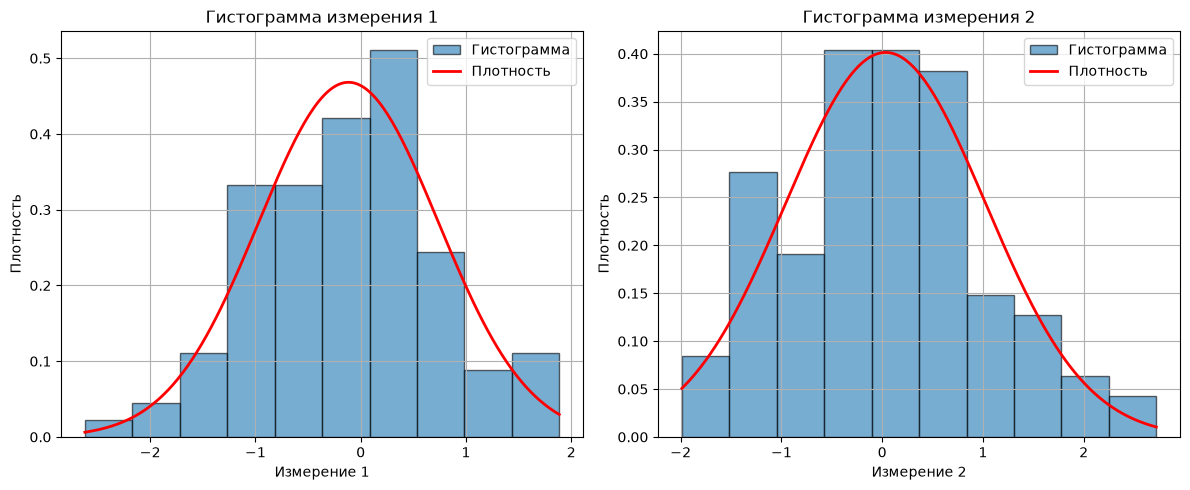

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, ax in enumerate(axes):
    data = points[:, i]

    ax.hist(data, bins=10, density=True, alpha=0.6,
            edgecolor="black", label="Гистограмма")

    x = np.linspace(data.min(), data.max(), 200)
    mean = data.mean()
    std = data.std()

    density = (
        1 / (std * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((x - mean) / std) ** 2)
    )

    ax.plot(x, density, color="red", linewidth=2,
            label="Плотность")

    ax.set_xlabel(f"Измерение {i + 1}")
    ax.set_ylabel("Плотность")
    ax.set_title(f"Гистограмма измерения {i + 1}")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

##Задание 3

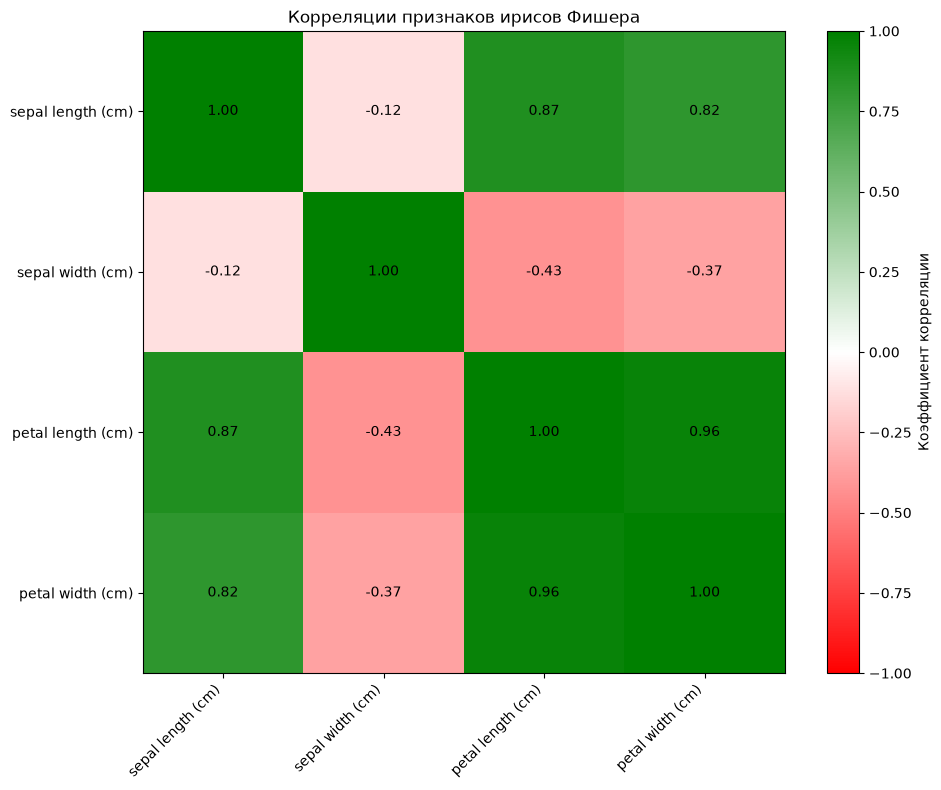

In [9]:
from sklearn.datasets import load_iris
from matplotlib.colors import LinearSegmentedColormap

iris = load_iris(as_frame=True)
data = iris.data

correlations = data.corr()

cmap = LinearSegmentedColormap.from_list(
    "correlation",
    ["red", "white", "green"]
)

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    correlations,
    cmap=cmap,
    vmin=-1,
    vmax=1
)

ax.set_xticks(np.arange(len(correlations.columns)))
ax.set_yticks(np.arange(len(correlations.columns)))

ax.set_xticklabels(correlations.columns, rotation=45, ha="right")
ax.set_yticklabels(correlations.columns)

for i in range(len(correlations)):
    for j in range(len(correlations)):
        ax.text(
            j, i, f"{correlations.iloc[i, j]:.2f}",
            ha="center", va="center", color="black"
        )

fig.colorbar(image, ax=ax, label="Коэффициент корреляции")
ax.set_title("Корреляции признаков ирисов Фишера")

plt.tight_layout()
plt.show()

##Задание 4

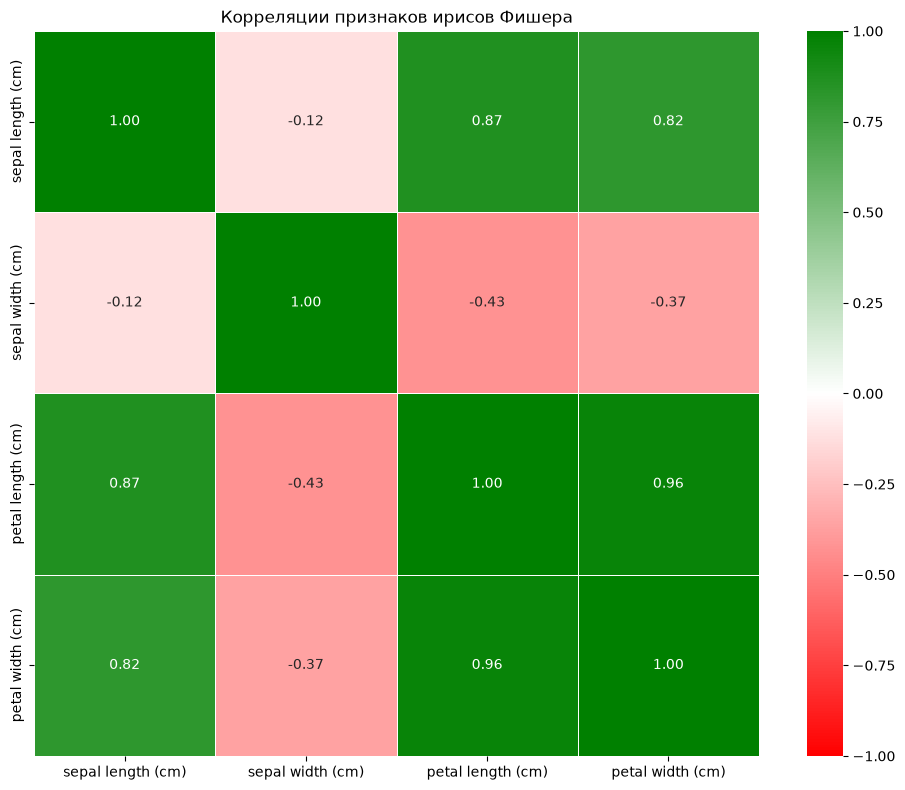

In [10]:
import seaborn as sns

cmap = LinearSegmentedColormap.from_list(
    "correlation",
    ["red", "white", "green"]
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap=cmap,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Корреляции признаков ирисов Фишера")
plt.tight_layout()
plt.show()